In [3]:
import numpy as np
import cv2 as cv
from google.colab.patches import cv2_imshow

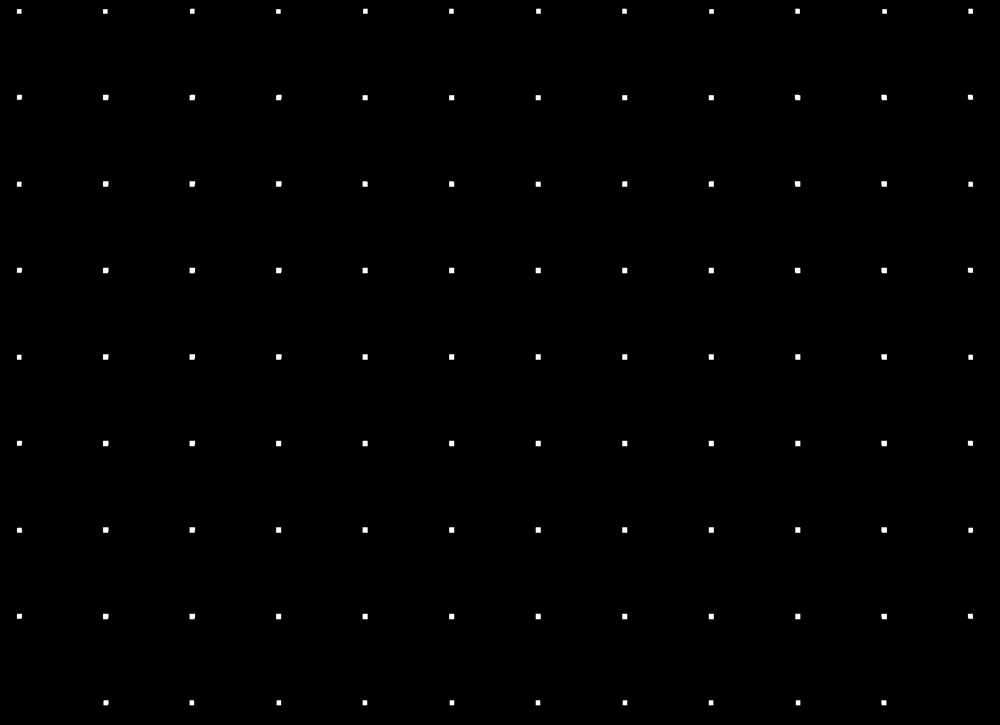

In [5]:
img=cv.imread('/content/checkerboard.png')
gray=cv.cvtColor(img,cv.COLOR_BGR2GRAY)
gray=np.float32(gray)

dst=cv.cornerHarris(src=gray,blockSize=2,ksize=3,k=0.04)

kernel=np.ones((9,9),np.uint8)
dst=cv.dilate(dst,kernel)

img[dst>0.01*dst.max()]=[0,0,255]#Red
cv2_imshow(dst)
if cv.waitKey(0):
    cv.destroyAllWindows()

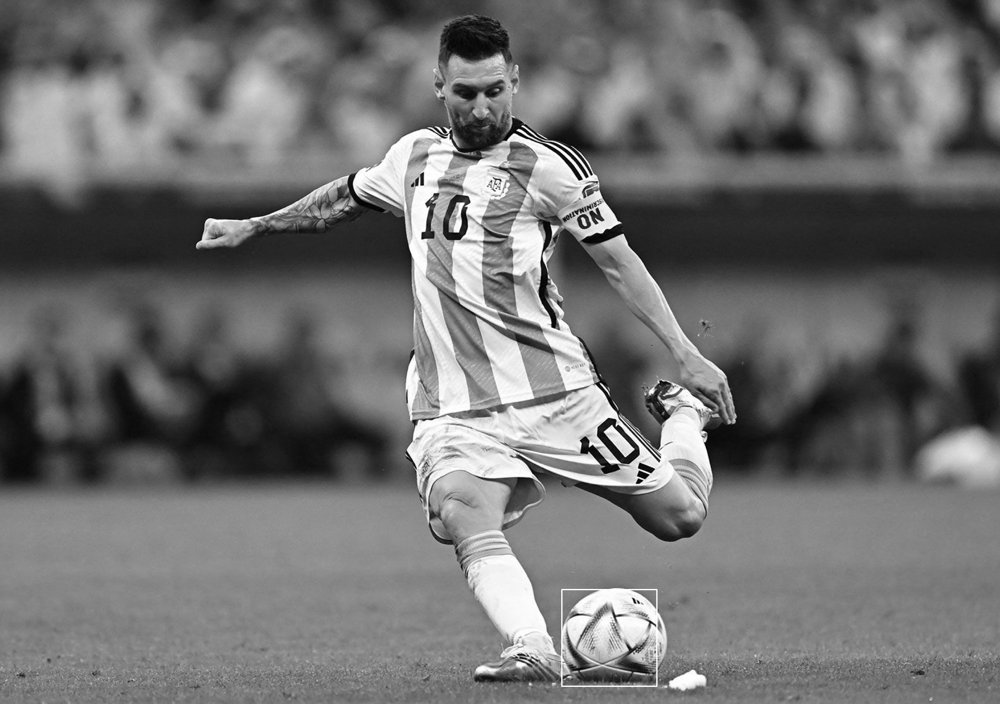

In [7]:
img=cv.imread('/content/messi.png',cv.IMREAD_GRAYSCALE)
img2=np.copy(img)

template=cv.imread('/content/football2.png',cv.IMREAD_GRAYSCALE)
w,h=template.shape

#Apply template matching

res=cv.matchTemplate(img,template,cv.TM_CCOEFF)
min_val,max_val,min_loc,max_loc=cv.minMaxLoc(res)

#Diagonal corners for rectangle
top_left=max_loc
bottom_right=(top_left[0]+w,top_left[1]+h)

#Draw Bounding box
cv.rectangle(img2,top_left,bottom_right,255,2)
cv2_imshow(img2)
if cv.waitKey(0):
    cv.destroyAllWindows()

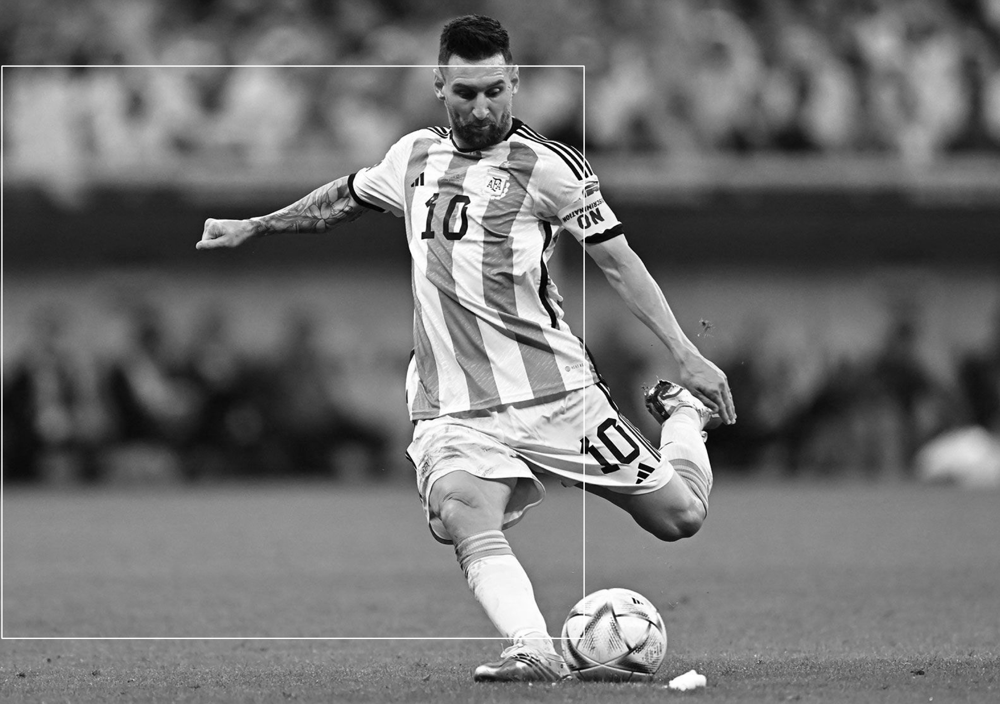

In [8]:
img=cv.imread('/content/messi.png',cv.IMREAD_GRAYSCALE)
img2=np.copy(img)

template=cv.imread('/content/football.png',cv.IMREAD_GRAYSCALE)
w,h=template.shape

#Apply template matching

res=cv.matchTemplate(img,template,cv.TM_CCOEFF)
min_val,max_val,min_loc,max_loc=cv.minMaxLoc(res)

#Diagonal corners for rectangle
top_left=max_loc
bottom_right=(top_left[0]+w,top_left[1]+h)

#Draw Bounding box
cv.rectangle(img2,top_left,bottom_right,255,2)
cv2_imshow(img2)
if cv.waitKey(0):
    cv.destroyAllWindows()

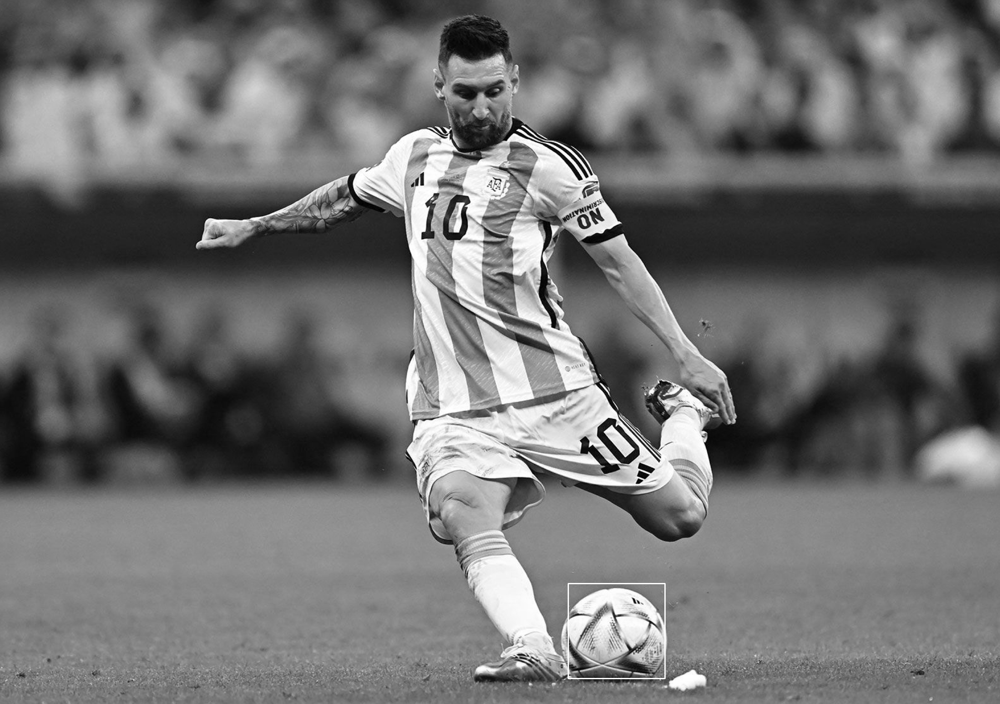

In [9]:
img=cv.imread('/content/messi.png',cv.IMREAD_GRAYSCALE)
img2=img.copy()
template=cv.imread('/content/football2.png',cv.IMREAD_GRAYSCALE)
h,w=template.shape

gray_img=np.float32(img2)
gray_template=np.float32(template)

#Find corners in both img and template
dst_img=cv.cornerHarris(gray_img,2,3,0.04)
dst_template=cv.cornerHarris(gray_template,2,3,0.04)

#Normalize Harris corner detected images
dst_img_norm=cv.normalize(dst_img,None, alpha=0,beta=255,
                          norm_type=cv.NORM_MINMAX,
                          dtype=cv.CV_8U)

dst_template_norm=cv.normalize(dst_template,None, alpha=0,beta=255,
                          norm_type=cv.NORM_MINMAX,
                          dtype=cv.CV_8U)
#Template Matching
res=cv.matchTemplate(dst_img_norm,dst_template_norm,cv.TM_CCOEFF)

min_val,max_val,min_loc,max_loc=cv.minMaxLoc(res)
top_left=max_loc
bottom_right=(top_left[0]+w,top_left[1]+h)
cv.rectangle(img2,top_left,bottom_right,255,2)
cv2_imshow(img2)
if cv.waitKey(0):
    cv.destroyAllWindows()

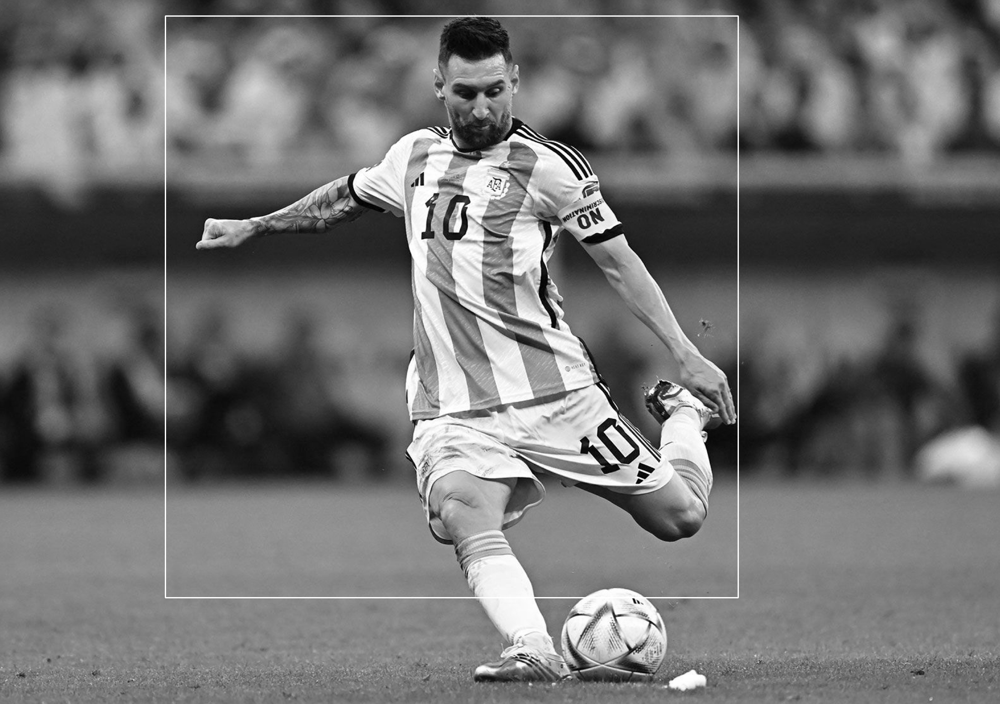

In [10]:
img=cv.imread('/content/messi.png',cv.IMREAD_GRAYSCALE)
img2=img.copy()
template=cv.imread('/content/football.png',cv.IMREAD_GRAYSCALE)
h,w=template.shape

gray_img=np.float32(img2)
gray_template=np.float32(template)

#Find corners in both img and template
dst_img=cv.cornerHarris(gray_img,2,3,0.04)
dst_template=cv.cornerHarris(gray_template,2,3,0.04)

#Normalize Harris corner detected images
dst_img_norm=cv.normalize(dst_img,None, alpha=0,beta=255,
                          norm_type=cv.NORM_MINMAX,
                          dtype=cv.CV_8U)

dst_template_norm=cv.normalize(dst_template,None, alpha=0,beta=255,
                          norm_type=cv.NORM_MINMAX,
                          dtype=cv.CV_8U)
#Template Matching
res=cv.matchTemplate(dst_img_norm,dst_template_norm,cv.TM_CCOEFF)

min_val,max_val,min_loc,max_loc=cv.minMaxLoc(res)
top_left=max_loc
bottom_right=(top_left[0]+w,top_left[1]+h)
cv.rectangle(img2,top_left,bottom_right,255,2)
cv2_imshow(img2)
if cv.waitKey(0):
    cv.destroyAllWindows()

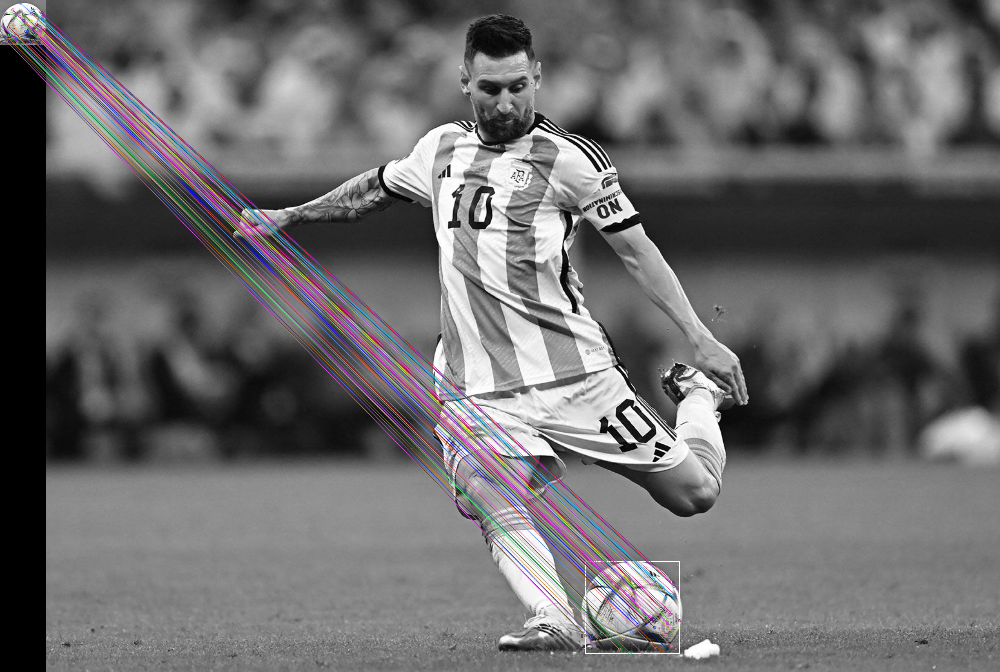

In [12]:
img=cv.imread("/content/messi.png",cv.IMREAD_GRAYSCALE)
img2=img.copy()
template=cv.imread("/content/football2.png",cv.IMREAD_GRAYSCALE)
scale_factor=0.5
template=cv.resize(template, None,fx=scale_factor,fy=scale_factor,
                   interpolation=cv.INTER_AREA)

#SIFT Feature Extraction
sift=cv.SIFT_create()

kp1,des1=sift.detectAndCompute(template,None)
kp2,des2=sift.detectAndCompute(img, None)

if des1 is None or des2 is None:
    print("No descriptor found")

flann=cv.FlannBasedMatcher(dict(algorithm=1,trees=5),dict(checks=50))
matches=flann.knnMatch(des1,des2,k=2)

good_matches=[]
for match in matches:
    if (len(match)==2):
        m,n=match
        if m.distance<0.75*n.distance:
            good_matches.append(m)

dst_points=np.array([kp2[m.trainIdx].pt for m in good_matches], dtype=np.float32)

x,y,w,h=cv.boundingRect(np.int32(dst_points))
cv.rectangle(img2,(x,y),(x+w,y+h),255,2)

match_img=cv.drawMatches(template,kp1,img2,kp2,good_matches,None,
                         flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

cv2_imshow(match_img)
if cv.waitKey(0):
    cv.destroyAllWindows()

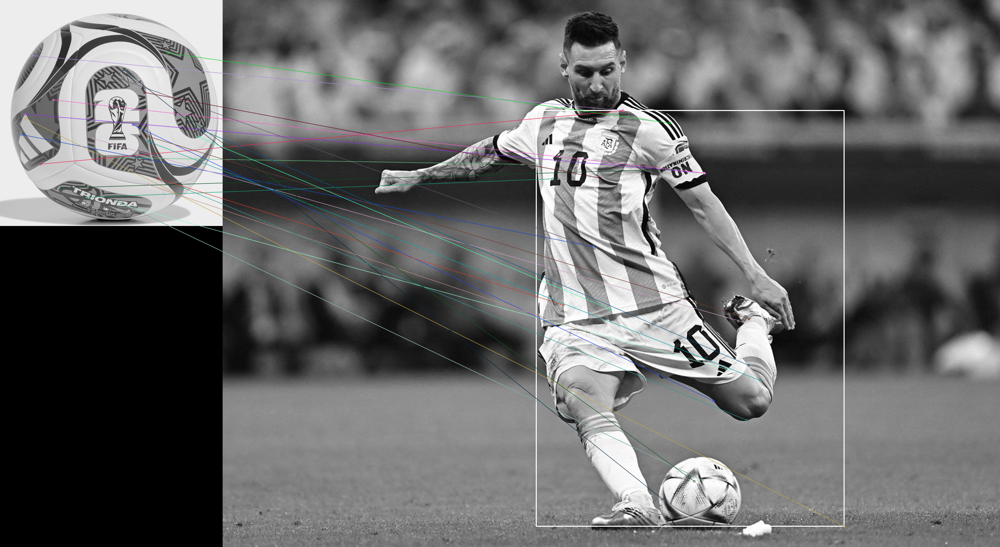

In [13]:
img=cv.imread("/content/messi.png",cv.IMREAD_GRAYSCALE)
img2=img.copy()
template=cv.imread("/content/football.png",cv.IMREAD_GRAYSCALE)
scale_factor=0.5
template=cv.resize(template, None,fx=scale_factor,fy=scale_factor,
                   interpolation=cv.INTER_AREA)

#SIFT Feature Extraction
sift=cv.SIFT_create()

kp1,des1=sift.detectAndCompute(template,None)
kp2,des2=sift.detectAndCompute(img, None)

if des1 is None or des2 is None:
    print("No descriptor found")

flann=cv.FlannBasedMatcher(dict(algorithm=1,trees=5),dict(checks=50))
matches=flann.knnMatch(des1,des2,k=2)

good_matches=[]
for match in matches:
    if (len(match)==2):
        m,n=match
        if m.distance<0.75*n.distance:
            good_matches.append(m)

dst_points=np.array([kp2[m.trainIdx].pt for m in good_matches], dtype=np.float32)

x,y,w,h=cv.boundingRect(np.int32(dst_points))
cv.rectangle(img2,(x,y),(x+w,y+h),255,2)

match_img=cv.drawMatches(template,kp1,img2,kp2,good_matches,None,
                         flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

cv2_imshow(match_img)
if cv.waitKey(0):
    cv.destroyAllWindows()

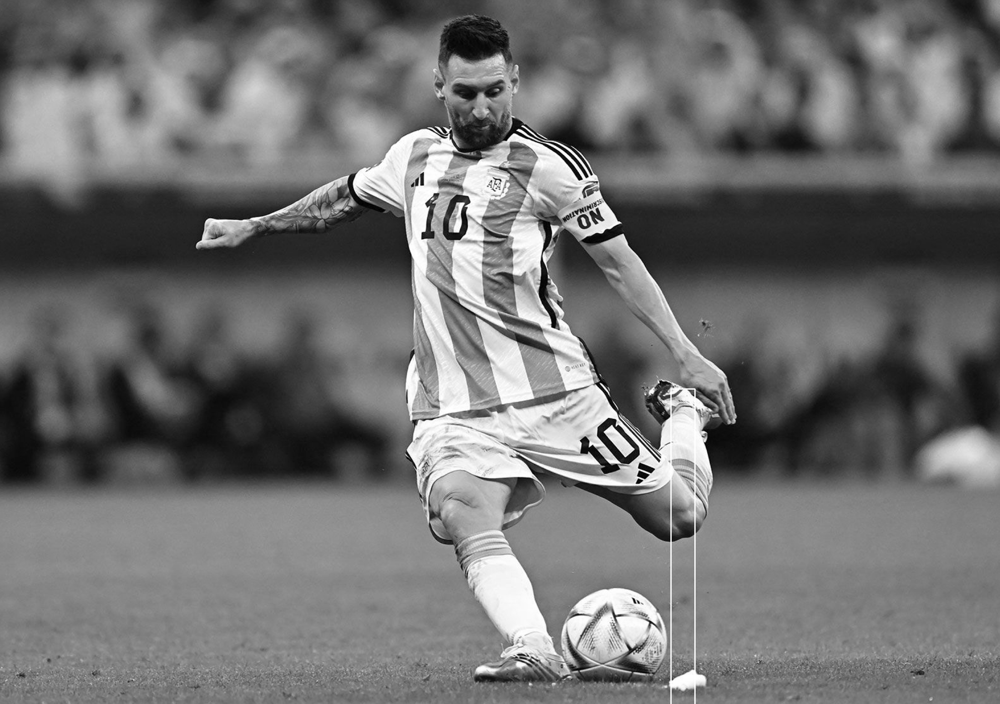

In [25]:
img=cv.imread("/content/messi.png",cv.IMREAD_GRAYSCALE)
img2=img.copy()
template=cv.imread("/content/football.png",cv.IMREAD_GRAYSCALE)
scale_factor=0.5
template=cv.resize(template, None,fx=scale_factor,fy=scale_factor,
                   interpolation=cv.INTER_AREA)

#SIFT Feature Extraction
sift=cv.SIFT_create()

kp1,des1=sift.detectAndCompute(template,None)
kp2,des2=sift.detectAndCompute(img, None)

if des1 is None or des2 is None:
    print("No descriptor found")

flann=cv.FlannBasedMatcher(dict(algorithm=1,trees=5),dict(checks=50))
matches=flann.knnMatch(des1,des2,k=2)

good_matches=[]
for match in matches:
    if (len(match)==2):
        m,n=match
        if m.distance<0.75*n.distance:
            good_matches.append(m)

src_pts=np.float32([kp1[m.queryIdx].pt for m in good_matches]).reshape(-1,1,2)
dst_points=np.float32([kp2[m.trainIdx].pt for m in good_matches]).reshape(-1,1,2)


M,mask=cv.findHomography(src_pts,dst_points,cv.RANSAC,5)
h,w=template.shape
pts=np.float32([[0,0],[0,h],[w,h],[w,0]]).reshape(-1,1,2)
dst=cv.perspectiveTransform(pts,M)

x,y,w,h=cv.boundingRect(np.int32(dst))
cv.rectangle(img2,(x,y),(x+w,y+h),255,2)

match_img=cv.drawMatches(template,kp1,img2,kp2,good_matches,None,
                         flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

cv2_imshow(img2)
if cv.waitKey(0):
    cv.destroyAllWindows()